# Section 9. Margin/Fee and Performance Reanalysis

발행마진 2%를 모든 전략에 동일하게 더하면 전략 순위는 크게 바뀌지 않는다. 이번 수정에서는 2%를 발행자가 보유하는 마진으로 볼 때와 외부 판매수수료로 지급되는 비용으로 볼 때를 분리하고, 동적헤지 리밸런싱 거래비용 및 정적 short put 거래비용 민감도를 함께 재분석한다.


## 수정: Section 9 재분석 범위

이번 section 9는 단순히 2억원을 terminal balance에 더하는 분석에서 확장한다. 2% 현금흐름을 `발행자가 보유하는 마진`, `마진/수수료 없음`, `외부 판매수수료 지급` 세 가지로 나누고, 동적헤지 리밸런싱 비용과 정적 short put open/close 비용을 cash account 관점에서 차감해 최적 조합이 어떻게 바뀌는지 확인한다.


In [1]:
# ============================================================
# Section 9. Margin-adjusted Performance Analysis
# Purpose: Add issuance margin to ELS business terminal balance
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from dataclasses import dataclass

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 120)
pd.set_option("display.float_format", "{:,.6f}".format)

SEED = 42
np.random.seed(SEED)

In [2]:
# ============================================================
# 9-0. Project Directory Setting
# ============================================================

PROJECT_NAME = "ELS hege 5.19"
CURRENT_DIR = Path.cwd()


def find_project_dir(project_name=PROJECT_NAME):
    """
    Resolve the local project folder from the notebook folder, a subfolder,
    or the parent workspace folder.
    """
    current = Path.cwd().resolve()

    if current.name == project_name:
        return current

    for parent in current.parents:
        if parent.name == project_name:
            return parent

    for base in [current, *current.parents]:
        candidate = base / project_name
        if candidate.exists():
            return candidate.resolve()

    return current / project_name


PROJECT_DIR = find_project_dir()

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "output"
FIGURE_DIR = PROJECT_DIR / "figures"
CODE_DIR = PROJECT_DIR

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

KOSPI200_PATH = DATA_DIR / "kospi200_close_new.csv"

print("CURRENT_DIR:", CURRENT_DIR)
print("PROJECT_DIR:", PROJECT_DIR)
print("DATA_DIR:", DATA_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)
print("FIGURE_DIR:", FIGURE_DIR)
print("CODE_DIR:", CODE_DIR)
print("KOSPI200_PATH:", KOSPI200_PATH)
print("Data file exists:", KOSPI200_PATH.exists())


CURRENT_DIR: c:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
PROJECT_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
DATA_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\data
OUTPUT_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output
FIGURE_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\figures
CODE_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
KOSPI200_PATH: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\data\kospi200_close_new.csv
Data file exists: True


# 9-1 상품 및 마진 가정

In [3]:
# ============================================================
# 9-1. Product and Margin Assumptions
# ============================================================

NOTIONAL = 10_000_000_000  # 100억원
ISSUANCE_MARGIN = 200_000_000  # 2억원

PRINCIPAL_DAILY_RATE = 0.03 / 365

margin_assumption = {
    "notional": NOTIONAL,
    "issuance_margin": ISSUANCE_MARGIN,
    "issuance_margin_ratio": ISSUANCE_MARGIN / NOTIONAL,
    "margin_treatment": (
        "Margin is received at issuance and invested at risk-free rate until final maturity. "
        "Existing hedge strategy outputs are reused without changing hedge allocation."
    )
}

margin_assumption

{'notional': 10000000000,
 'issuance_margin': 200000000,
 'issuance_margin_ratio': 0.02,
 'margin_treatment': 'Margin is received at issuance and invested at risk-free rate until final maturity. Existing hedge strategy outputs are reused without changing hedge allocation.'}

In [4]:
# ============================================================
# 9-2. Load Existing Outputs
# ============================================================

# Simulation dates
sim_dates = pd.read_csv(OUTPUT_DIR / "sim_dates.csv")
sim_dates["Date"] = pd.to_datetime(sim_dates["Date"])
sim_dates = pd.DatetimeIndex(sim_dates["Date"])

# Payoff result
payoff_df = pd.read_csv(OUTPUT_DIR / "els_payoff_result.csv")

# Experiment grid
experiment_grid = pd.read_csv(OUTPUT_DIR / "experiment_grid.csv")
experiment_grid = experiment_grid.copy()
experiment_grid["experiment_id"] = np.arange(len(experiment_grid))

# Static hedge PnL from Section 5
static_pnl_terminal_matrix = np.load(
    OUTPUT_DIR / "static_pnl_terminal_matrix.npy"
)

# Dynamic hedge account from Section 6
dynamic_terminal_account_matrix = np.load(
    OUTPUT_DIR / "dynamic_terminal_account_matrix.npy"
)

# Optional: previous terminal balance, for comparison only
previous_terminal_balance_path = OUTPUT_DIR / "terminal_balance_matrix.npy"

if previous_terminal_balance_path.exists():
    previous_terminal_balance_matrix = np.load(previous_terminal_balance_path)
    print("Loaded previous terminal balance matrix.")
else:
    previous_terminal_balance_matrix = None
    print("Previous terminal balance matrix not found. We will recompute baseline.")

print("Number of experiments:", len(experiment_grid))
print("Number of paths:", len(payoff_df))
print("static_pnl_terminal_matrix shape:", static_pnl_terminal_matrix.shape)
print("dynamic_terminal_account_matrix shape:", dynamic_terminal_account_matrix.shape)

display(experiment_grid.head())
display(payoff_df.head())

Loaded previous terminal balance matrix.
Number of experiments: 33
Number of paths: 10000
static_pnl_terminal_matrix shape: (33, 10000)
dynamic_terminal_account_matrix shape: (33, 10000)


,principal_book_ratio,hedge_book_ratio,principal_book_amount,hedge_book_amount,static_ratio,dynamic_ratio,static_budget,dynamic_budget,experiment_id
0,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.000000,1.000000,0.000000,"7,000,000,000.000000",0
1,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.100000,0.900000,"700,000,000.000000","6,300,000,000.000000",1
2,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.200000,0.800000,"1,400,000,000.000000","5,600,000,000.000000",2
3,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.300000,0.700000,"2,100,000,000.000000","4,900,000,000.000000",3
4,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.400000,0.600000,"2,800,000,000.000000","4,200,000,000.000000",4


,path_id,autocall_occurred,autocall_no,settlement_index,elapsed_years,knock_in_occurred,final_price,min_price,payoff_type,investor_payoff,issuer_cash_outflow,investor_return_rate
0,0,True,1,128,0.500000,False,85.148390,73.958330,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
1,1,True,1,128,0.500000,False,382.028553,99.089556,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
2,2,True,1,128,0.500000,False,130.545363,83.432437,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
3,3,True,1,128,0.500000,False,88.593817,77.338565,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
4,4,True,1,128,0.500000,False,73.937730,73.937730,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500


# 9-3 growth factor 계산

In [5]:
# ============================================================
# 9-3. Growth Factors
# ============================================================

def cash_growth_factor_by_calendar_days(n_days, daily_rate=PRINCIPAL_DAILY_RATE):
    return (1 + daily_rate) ** n_days


n_paths = len(payoff_df)
n_experiments = len(experiment_grid)

settlement_index = payoff_df["settlement_index"].astype(int).values
issuer_cash_outflow = payoff_df["issuer_cash_outflow"].astype(float).values

issue_date = sim_dates[0]
final_date = sim_dates[-1]

settlement_dates = sim_dates[settlement_index]

days_to_settlement = np.array([
    (d - issue_date).days for d in settlement_dates
])

days_settlement_to_maturity = np.array([
    (final_date - d).days for d in settlement_dates
])

total_days_to_maturity = (final_date - issue_date).days

growth_to_settlement = cash_growth_factor_by_calendar_days(days_to_settlement)
growth_settlement_to_maturity = cash_growth_factor_by_calendar_days(days_settlement_to_maturity)
growth_full_maturity = cash_growth_factor_by_calendar_days(total_days_to_maturity)

print("Issue date:", issue_date)
print("Final date:", final_date)
print("Total calendar days:", total_days_to_maturity)
print("Growth full maturity:", growth_full_maturity)

Issue date: 2026-05-14 00:00:00
Final date: 2029-05-09 00:00:00
Total calendar days: 1091
Growth full maturity: 1.093810583691778


In [6]:
# ============================================================
# 9-4. Recompute Baseline Terminal Balance Clearly
# ============================================================

principal_account_terminal_matrix = np.zeros((n_experiments, n_paths))
static_hedge_account_terminal_matrix = np.zeros((n_experiments, n_paths))
payoff_terminal_equivalent_matrix = np.zeros((n_experiments, n_paths))

for i, row in experiment_grid.iterrows():
    principal_amount = float(row["principal_book_amount"])
    static_budget = float(row["static_budget"])
    
    # 1. 원금북: 채권팀 운용 계좌
    principal_account_terminal = principal_amount * growth_full_maturity
    
    # 2. 정적헤지 계좌: static budget의 현금성 잔고 + static hedge PnL
    static_cash_collateral_terminal = static_budget * growth_full_maturity
    static_hedge_account_terminal = (
        static_cash_collateral_terminal
        + static_pnl_terminal_matrix[i, :]
    )
    
    # 3. payoff: settlement 시점 지급액을 만기시점 가치로 환산
    payoff_terminal_equivalent = issuer_cash_outflow * growth_settlement_to_maturity
    
    principal_account_terminal_matrix[i, :] = principal_account_terminal
    static_hedge_account_terminal_matrix[i, :] = static_hedge_account_terminal
    payoff_terminal_equivalent_matrix[i, :] = payoff_terminal_equivalent


baseline_terminal_balance_matrix = (
    principal_account_terminal_matrix
    + static_hedge_account_terminal_matrix
    + dynamic_terminal_account_matrix
    - payoff_terminal_equivalent_matrix
)

print("baseline_terminal_balance_matrix shape:", baseline_terminal_balance_matrix.shape)
pd.Series(baseline_terminal_balance_matrix[0]).describe()

baseline_terminal_balance_matrix shape: (33, 10000)


count           10,000.000000
mean      -632,615,986.757715
std      1,167,812,459.561454
min     -7,757,417,939.755375
25%       -657,751,549.752254
50%       -628,592,243.485954
75%       -594,562,158.643138
max      9,244,996,160.402613
dtype: float64

# 9-5. 발행마진 2억 발행

발행마진은 발행 시점에 수취한 뒤 만기까지 risk-free rate로 운용한다고 두자

In [7]:
# ============================================================
# 9-5. Add Issuance Margin
# ============================================================

margin_terminal_value = ISSUANCE_MARGIN * growth_full_maturity

margin_terminal_matrix = np.full(
    shape=(n_experiments, n_paths),
    fill_value=margin_terminal_value
)

terminal_balance_with_margin_matrix = (
    baseline_terminal_balance_matrix
    + margin_terminal_matrix
)

print("Issuance margin:", ISSUANCE_MARGIN)
print("Margin terminal value:", margin_terminal_value)
print("Margin terminal value, 100m KRW:", margin_terminal_value / 1e8)

pd.Series(terminal_balance_with_margin_matrix[0]).describe()

Issuance margin: 200000000
Margin terminal value: 218762116.7383556
Margin terminal value, 100m KRW: 2.187621167383556


count           10,000.000000
mean      -413,853,870.019359
std      1,167,812,459.561454
min     -7,538,655,823.017019
25%       -438,989,433.013898
50%       -409,830,126.747599
75%       -375,800,041.904782
max      9,463,758,277.140968
dtype: float64

# 9-6 마진 반영 전후 성과 요약

In [8]:
# ============================================================
# 9-6. Performance Summary Before and After Margin
# ============================================================

margin_summary_list = []

for i, row in experiment_grid.iterrows():
    base_tb = baseline_terminal_balance_matrix[i, :]
    margin_tb = terminal_balance_with_margin_matrix[i, :]
    
    margin_summary_list.append({
        "experiment_id": int(row["experiment_id"]),
        
        "principal_book_ratio": row["principal_book_ratio"],
        "hedge_book_ratio": row["hedge_book_ratio"],
        "static_ratio": row["static_ratio"],
        "dynamic_ratio": row["dynamic_ratio"],
        
        "principal_book_amount": row["principal_book_amount"],
        "hedge_book_amount": row["hedge_book_amount"],
        "static_budget": row["static_budget"],
        "dynamic_budget": row["dynamic_budget"],
        
        "issuance_margin": ISSUANCE_MARGIN,
        "margin_terminal_value": margin_terminal_value,
        
        # Before margin
        "mean_terminal_balance_before_margin": np.mean(base_tb),
        "std_terminal_balance_before_margin": np.std(base_tb, ddof=1),
        "min_terminal_balance_before_margin": np.min(base_tb),
        "p01_terminal_balance_before_margin": np.percentile(base_tb, 1),
        "p05_terminal_balance_before_margin": np.percentile(base_tb, 5),
        "p50_terminal_balance_before_margin": np.percentile(base_tb, 50),
        "p95_terminal_balance_before_margin": np.percentile(base_tb, 95),
        "prob_negative_before_margin": np.mean(base_tb < 0),
        "prob_below_notional_before_margin": np.mean(base_tb < NOTIONAL),
        
        # After margin
        "mean_terminal_balance_after_margin": np.mean(margin_tb),
        "std_terminal_balance_after_margin": np.std(margin_tb, ddof=1),
        "min_terminal_balance_after_margin": np.min(margin_tb),
        "p01_terminal_balance_after_margin": np.percentile(margin_tb, 1),
        "p05_terminal_balance_after_margin": np.percentile(margin_tb, 5),
        "p50_terminal_balance_after_margin": np.percentile(margin_tb, 50),
        "p95_terminal_balance_after_margin": np.percentile(margin_tb, 95),
        "prob_negative_after_margin": np.mean(margin_tb < 0),
        "prob_below_notional_after_margin": np.mean(margin_tb < NOTIONAL),
        
        # Difference
        "mean_margin_effect": np.mean(margin_tb) - np.mean(base_tb),
        "p05_margin_effect": np.percentile(margin_tb, 5) - np.percentile(base_tb, 5),
    })

margin_summary = pd.DataFrame(margin_summary_list)

# risk-adjusted score after margin
margin_summary["risk_adjusted_score_after_margin"] = (
    margin_summary["mean_terminal_balance_after_margin"]
    - 0.5 * margin_summary["std_terminal_balance_after_margin"]
)

display(margin_summary.head())

,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,principal_book_amount,hedge_book_amount,static_budget,dynamic_budget,issuance_margin,margin_terminal_value,mean_terminal_balance_before_margin,std_terminal_balance_before_margin,min_terminal_balance_before_margin,p01_terminal_balance_before_margin,p05_terminal_balance_before_margin,p50_terminal_balance_before_margin,p95_terminal_balance_before_margin,prob_negative_before_margin,prob_below_notional_before_margin,mean_terminal_balance_after_margin,std_terminal_balance_after_margin,min_terminal_balance_after_margin,p01_terminal_balance_after_margin,p05_terminal_balance_after_margin,p50_terminal_balance_after_margin,p95_terminal_balance_after_margin,prob_negative_after_margin,prob_below_notional_after_margin,mean_margin_effect,p05_margin_effect,risk_adjusted_score_after_margin
0,0,0.300000,0.700000,0.000000,1.000000,"3,000,000,000.000000","7,000,000,000.000000",0.000000,"7,000,000,000.000000",200000000,"218,762,116.738356","-632,615,986.757715","1,167,812,459.561455","-7,757,417,939.755375","-3,918,956,510.408398","-2,227,219,144.914642","-628,592,243.485954","450,750,982.258473",0.911700,1.000000,"-413,853,870.019359","1,167,812,459.561455","-7,538,655,823.017019","-3,700,194,393.670043","-2,008,457,028.176286","-409,830,126.747599","669,513,098.996828",0.882500,1.000000,"218,762,116.738356","218,762,116.738356","-997,760,099.800086"
1,1,0.300000,0.700000,0.100000,0.900000,"3,000,000,000.000000","7,000,000,000.000000","700,000,000.000000","6,300,000,000.000000",200000000,"218,762,116.738356","-612,426,583.600082","1,118,523,036.629080","-7,141,617,038.626154","-3,638,714,385.414130","-2,215,185,397.519274","-590,374,950.382275","371,286,538.490874",0.914800,1.000000,"-393,664,466.861726","1,118,523,036.629080","-6,922,854,921.887798","-3,419,952,268.675775","-1,996,423,280.780918","-371,612,833.643919","590,048,655.229230",0.884100,1.000000,"218,762,116.738356","218,762,116.738356","-952,925,985.176266"
2,2,0.300000,0.700000,0.200000,0.800000,"3,000,000,000.000000","7,000,000,000.000000","1,400,000,000.000000","5,600,000,000.000000",200000000,"218,762,116.738356","-592,237,180.442451","1,072,753,249.950742","-6,525,816,137.496934","-3,266,916,924.521206","-2,196,265,491.917036","-551,289,679.817545","297,915,032.910644",0.918900,1.000000,"-373,475,063.704095","1,072,753,249.950742","-6,307,054,020.758578","-3,048,154,807.782850","-1,977,503,375.178680","-332,527,563.079189","516,677,149.649000",0.884600,1.000000,"218,762,116.738356","218,762,116.738356","-909,851,688.679466"
3,3,0.300000,0.700000,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000","2,100,000,000.000000","4,900,000,000.000000",200000000,"218,762,116.738356","-572,047,777.284819","1,030,971,966.707533","-5,942,801,324.481939","-3,010,274,302.254836","-2,176,185,763.102603","-513,621,570.476407","218,516,390.694873",0.924200,1.000000,"-353,285,660.546464","1,030,971,966.707533","-5,724,039,207.743584","-2,791,512,185.516480","-1,957,423,646.364248","-294,859,453.738051","437,278,507.433229",0.885600,1.000000,"218,762,116.738356","218,762,116.738356","-868,771,643.900230"
4,4,0.300000,0.700000,0.400000,0.600000,"3,000,000,000.000000","7,000,000,000.000000","2,800,000,000.000000","4,200,000,000.000000",200000000,"218,762,116.738356","-551,858,374.127187","993,682,427.157035","-5,568,687,113.443436","-3,105,207,663.241333","-2,149,209,175.752726","-476,949,410.947355","149,322,243.556035",0.929400,1.000000,"-333,096,257.388831","993,682,427.157035","-5,349,924,996.705080","-2,886,445,546.502978","-1,930,447,059.014370","-258,187,294.209000","368,084,360.294390",0.888400,1.000000,"218,762,116.738356","218,762,116.738355","-829,937,470.967349"


# 9-7 마진 반영 후 최적 조합 랭킹

In [9]:
# ============================================================
# 9-7. Ranking After Margin
# ============================================================

rank_after_margin_by_mean = margin_summary.sort_values(
    "mean_terminal_balance_after_margin",
    ascending=False
).reset_index(drop=True)

rank_after_margin_by_p05 = margin_summary.sort_values(
    "p05_terminal_balance_after_margin",
    ascending=False
).reset_index(drop=True)

rank_after_margin_by_score = margin_summary.sort_values(
    "risk_adjusted_score_after_margin",
    ascending=False
).reset_index(drop=True)

ranking_cols = [
    "experiment_id",
    "principal_book_ratio",
    "hedge_book_ratio",
    "static_ratio",
    "dynamic_ratio",
    "mean_terminal_balance_before_margin",
    "mean_terminal_balance_after_margin",
    "p05_terminal_balance_before_margin",
    "p05_terminal_balance_after_margin",
    "prob_negative_before_margin",
    "prob_negative_after_margin",
    "prob_below_notional_before_margin",
    "prob_below_notional_after_margin",
    "risk_adjusted_score_after_margin",
]

print("Top 10 after margin by mean terminal balance")
display(rank_after_margin_by_mean[ranking_cols].head(10))

print("Top 10 after margin by 5% terminal balance")
display(rank_after_margin_by_p05[ranking_cols].head(10))

print("Top 10 after margin by risk-adjusted score")
display(rank_after_margin_by_score[ranking_cols].head(10))

Top 10 after margin by mean terminal balance


,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,mean_terminal_balance_before_margin,mean_terminal_balance_after_margin,p05_terminal_balance_before_margin,p05_terminal_balance_after_margin,prob_negative_before_margin,prob_negative_after_margin,prob_below_notional_before_margin,prob_below_notional_after_margin,risk_adjusted_score_after_margin
0,10,0.300000,0.700000,1.000000,0.000000,"-430,721,955.181397","-211,959,838.443041","-1,599,408,928.463154","-1,380,646,811.724798",0.986700,0.632800,1.000000,1.000000,"-657,709,284.727220"
1,21,0.500000,0.500000,1.000000,0.000000,"-432,225,666.474645","-213,463,549.736290","-1,692,232,657.797279","-1,473,470,541.058924",0.987000,0.733600,1.000000,1.000000,"-659,794,258.936280"
2,32,0.700000,0.300000,1.000000,0.000000,"-434,037,833.112640","-215,275,716.374285","-1,804,097,259.911257","-1,585,335,143.172901",0.987000,0.961600,1.000000,1.000000,"-675,001,395.837937"
3,31,0.700000,0.300000,0.900000,0.100000,"-442,566,421.494655","-223,804,304.756299","-1,836,131,446.200453","-1,617,369,329.462097",0.987000,0.966500,1.000000,1.000000,"-687,165,865.970832"
4,20,0.500000,0.500000,0.900000,0.100000,"-446,548,555.032833","-227,786,438.294478","-1,741,415,503.427895","-1,522,653,386.689539",0.986600,0.812200,1.000000,1.000000,"-677,071,961.356321"
5,9,0.300000,0.700000,0.900000,0.100000,"-450,911,358.339028","-232,149,241.600672","-1,663,880,839.357903","-1,445,118,722.619547",0.984000,0.702800,1.000000,1.000000,"-678,210,126.252321"
6,30,0.700000,0.300000,0.800000,0.200000,"-451,095,009.876669","-232,332,893.138314","-1,868,207,951.613167","-1,649,445,834.874811",0.986300,0.942000,1.000000,1.000000,"-700,251,476.430624"
7,29,0.700000,0.300000,0.700000,0.300000,"-459,623,598.258684","-240,861,481.520328","-1,899,461,020.906871","-1,680,698,904.168515",0.980300,0.924200,1.000000,1.000000,"-714,231,625.166561"
8,19,0.500000,0.500000,0.800000,0.200000,"-460,871,443.591021","-242,109,326.852666","-1,791,006,102.776206","-1,572,243,986.037850",0.981100,0.880700,1.000000,1.000000,"-696,471,927.516338"
9,28,0.700000,0.300000,0.600000,0.400000,"-468,152,186.640698","-249,390,069.902343","-1,931,660,601.317339","-1,712,898,484.578983",0.970200,0.913400,1.000000,1.000000,"-729,075,814.246791"


Top 10 after margin by 5% terminal balance


,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,mean_terminal_balance_before_margin,mean_terminal_balance_after_margin,p05_terminal_balance_before_margin,p05_terminal_balance_after_margin,prob_negative_before_margin,prob_negative_after_margin,prob_below_notional_before_margin,prob_below_notional_after_margin,risk_adjusted_score_after_margin
0,10,0.300000,0.700000,1.000000,0.000000,"-430,721,955.181397","-211,959,838.443041","-1,599,408,928.463154","-1,380,646,811.724798",0.986700,0.632800,1.000000,1.000000,"-657,709,284.727220"
1,9,0.300000,0.700000,0.900000,0.100000,"-450,911,358.339028","-232,149,241.600672","-1,663,880,839.357903","-1,445,118,722.619547",0.984000,0.702800,1.000000,1.000000,"-678,210,126.252321"
2,21,0.500000,0.500000,1.000000,0.000000,"-432,225,666.474645","-213,463,549.736290","-1,692,232,657.797279","-1,473,470,541.058924",0.987000,0.733600,1.000000,1.000000,"-659,794,258.936280"
3,8,0.300000,0.700000,0.800000,0.200000,"-471,100,761.496660","-252,338,644.758304","-1,728,632,570.434266","-1,509,870,453.695910",0.973900,0.790000,1.000000,1.000000,"-702,169,206.227304"
4,20,0.500000,0.500000,0.900000,0.100000,"-446,548,555.032833","-227,786,438.294478","-1,741,415,503.427895","-1,522,653,386.689539",0.986600,0.812200,1.000000,1.000000,"-677,071,961.356321"
5,19,0.500000,0.500000,0.800000,0.200000,"-460,871,443.591021","-242,109,326.852666","-1,791,006,102.776206","-1,572,243,986.037850",0.981100,0.880700,1.000000,1.000000,"-696,471,927.516338"
6,7,0.300000,0.700000,0.700000,0.300000,"-491,290,164.654292","-272,528,047.915936","-1,796,446,061.448592","-1,577,683,944.710236",0.961900,0.873900,1.000000,1.000000,"-729,500,949.200644"
7,32,0.700000,0.300000,1.000000,0.000000,"-434,037,833.112640","-215,275,716.374285","-1,804,097,259.911257","-1,585,335,143.172901",0.987000,0.961600,1.000000,1.000000,"-675,001,395.837937"
8,31,0.700000,0.300000,0.900000,0.100000,"-442,566,421.494655","-223,804,304.756299","-1,836,131,446.200453","-1,617,369,329.462097",0.987000,0.966500,1.000000,1.000000,"-687,165,865.970832"
9,18,0.500000,0.500000,0.700000,0.300000,"-475,194,332.149208","-256,432,215.410853","-1,840,392,825.265666","-1,621,630,708.527310",0.969100,0.903000,1.000000,1.000000,"-717,924,118.830263"


Top 10 after margin by risk-adjusted score


,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,mean_terminal_balance_before_margin,mean_terminal_balance_after_margin,p05_terminal_balance_before_margin,p05_terminal_balance_after_margin,prob_negative_before_margin,prob_negative_after_margin,prob_below_notional_before_margin,prob_below_notional_after_margin,risk_adjusted_score_after_margin
0,10,0.300000,0.700000,1.000000,0.000000,"-430,721,955.181397","-211,959,838.443041","-1,599,408,928.463154","-1,380,646,811.724798",0.986700,0.632800,1.000000,1.000000,"-657,709,284.727220"
1,21,0.500000,0.500000,1.000000,0.000000,"-432,225,666.474645","-213,463,549.736290","-1,692,232,657.797279","-1,473,470,541.058924",0.987000,0.733600,1.000000,1.000000,"-659,794,258.936280"
2,32,0.700000,0.300000,1.000000,0.000000,"-434,037,833.112640","-215,275,716.374285","-1,804,097,259.911257","-1,585,335,143.172901",0.987000,0.961600,1.000000,1.000000,"-675,001,395.837937"
3,20,0.500000,0.500000,0.900000,0.100000,"-446,548,555.032833","-227,786,438.294478","-1,741,415,503.427895","-1,522,653,386.689539",0.986600,0.812200,1.000000,1.000000,"-677,071,961.356321"
4,9,0.300000,0.700000,0.900000,0.100000,"-450,911,358.339028","-232,149,241.600672","-1,663,880,839.357903","-1,445,118,722.619547",0.984000,0.702800,1.000000,1.000000,"-678,210,126.252321"
5,31,0.700000,0.300000,0.900000,0.100000,"-442,566,421.494655","-223,804,304.756299","-1,836,131,446.200453","-1,617,369,329.462097",0.987000,0.966500,1.000000,1.000000,"-687,165,865.970832"
6,19,0.500000,0.500000,0.800000,0.200000,"-460,871,443.591021","-242,109,326.852666","-1,791,006,102.776206","-1,572,243,986.037850",0.981100,0.880700,1.000000,1.000000,"-696,471,927.516338"
7,30,0.700000,0.300000,0.800000,0.200000,"-451,095,009.876669","-232,332,893.138314","-1,868,207,951.613167","-1,649,445,834.874811",0.986300,0.942000,1.000000,1.000000,"-700,251,476.430624"
8,8,0.300000,0.700000,0.800000,0.200000,"-471,100,761.496660","-252,338,644.758304","-1,728,632,570.434266","-1,509,870,453.695910",0.973900,0.790000,1.000000,1.000000,"-702,169,206.227304"
9,29,0.700000,0.300000,0.700000,0.300000,"-459,623,598.258684","-240,861,481.520328","-1,899,461,020.906871","-1,680,698,904.168515",0.980300,0.924200,1.000000,1.000000,"-714,231,625.166561"


# 9-8 recommended strategies after margin

In [10]:
# ============================================================
# 9-8. Recommended Strategies After Margin
# ============================================================

# 1. 평균 terminal balance 기준 최적 조합
recommended_by_mean = rank_after_margin_by_mean.iloc[0].copy()
recommended_by_mean_id = int(recommended_by_mean["experiment_id"])

# 2. 5% terminal balance 기준 최적 조합
recommended_by_p05 = rank_after_margin_by_p05.iloc[0].copy()
recommended_by_p05_id = int(recommended_by_p05["experiment_id"])

# 3. risk-adjusted score 기준 최적 조합
recommended_by_score = rank_after_margin_by_score.iloc[0].copy()
recommended_by_score_id = int(recommended_by_score["experiment_id"])


recommendation_cols = [
    "experiment_id",
    "principal_book_ratio",
    "hedge_book_ratio",
    "static_ratio",
    "dynamic_ratio",
    "mean_terminal_balance_after_margin",
    "std_terminal_balance_after_margin",
    "p05_terminal_balance_after_margin",
    "p50_terminal_balance_after_margin",
    "prob_negative_after_margin",
    "prob_below_notional_after_margin",
    "risk_adjusted_score_after_margin",
]

recommended_strategies = pd.DataFrame([
    {
        "selection_criterion": "Max Mean Terminal Balance",
        **recommended_by_mean[recommendation_cols].to_dict()
    },
    {
        "selection_criterion": "Max 5% Terminal Balance",
        **recommended_by_p05[recommendation_cols].to_dict()
    },
    {
        "selection_criterion": "Max Risk-adjusted Score",
        **recommended_by_score[recommendation_cols].to_dict()
    },
])

# 억원 단위 표시 컬럼 추가
money_cols = [
    "mean_terminal_balance_after_margin",
    "std_terminal_balance_after_margin",
    "p05_terminal_balance_after_margin",
    "p50_terminal_balance_after_margin",
    "risk_adjusted_score_after_margin",
]

for col in money_cols:
    recommended_strategies[col + "_100m"] = recommended_strategies[col] / 1e8

display(recommended_strategies)

print("Recommended by mean ID:", recommended_by_mean_id)
print("Recommended by p05 ID:", recommended_by_p05_id)
print("Recommended by score ID:", recommended_by_score_id)

,selection_criterion,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,mean_terminal_balance_after_margin,std_terminal_balance_after_margin,p05_terminal_balance_after_margin,p50_terminal_balance_after_margin,prob_negative_after_margin,prob_below_notional_after_margin,risk_adjusted_score_after_margin,mean_terminal_balance_after_margin_100m,std_terminal_balance_after_margin_100m,p05_terminal_balance_after_margin_100m,p50_terminal_balance_after_margin_100m,risk_adjusted_score_after_margin_100m
0,Max Mean Terminal Balance,10.000000,0.300000,0.700000,1.000000,0.000000,"-211,959,838.443041","891,498,892.568358","-1,380,646,811.724798","-68,769,734.494440",0.632800,1.000000,"-657,709,284.727220",-2.119598,8.914989,-13.806468,-0.687697,-6.577093
1,Max 5% Terminal Balance,10.000000,0.300000,0.700000,1.000000,0.000000,"-211,959,838.443041","891,498,892.568358","-1,380,646,811.724798","-68,769,734.494440",0.632800,1.000000,"-657,709,284.727220",-2.119598,8.914989,-13.806468,-0.687697,-6.577093
2,Max Risk-adjusted Score,10.000000,0.300000,0.700000,1.000000,0.000000,"-211,959,838.443041","891,498,892.568358","-1,380,646,811.724798","-68,769,734.494440",0.632800,1.000000,"-657,709,284.727220",-2.119598,8.914989,-13.806468,-0.687697,-6.577093


Recommended by mean ID: 10
Recommended by p05 ID: 10
Recommended by score ID: 10


# 9-9 pathwise results for mean vs 5% strategies

In [11]:
# ============================================================
# 9-9. Pathwise Results for Mean vs 5% Strategies
# ============================================================

def make_pathwise_result(experiment_id, strategy_name):
    base_tb = baseline_terminal_balance_matrix[experiment_id, :]
    margin_tb = terminal_balance_with_margin_matrix[experiment_id, :]
    
    result_df = pd.DataFrame({
        "strategy_name": strategy_name,
        "experiment_id": experiment_id,
        "path_id": payoff_df["path_id"],
        "payoff_type": payoff_df["payoff_type"],
        "autocall_no": payoff_df["autocall_no"],
        "knock_in_occurred": payoff_df["knock_in_occurred"],
        
        "principal_account_terminal": principal_account_terminal_matrix[experiment_id, :],
        "static_hedge_account_terminal": static_hedge_account_terminal_matrix[experiment_id, :],
        "dynamic_hedge_account_terminal": dynamic_terminal_account_matrix[experiment_id, :],
        "payoff_terminal_equivalent": payoff_terminal_equivalent_matrix[experiment_id, :],
        "margin_terminal_value": margin_terminal_matrix[experiment_id, :],
        
        "terminal_balance_before_margin": base_tb,
        "terminal_balance_after_margin": margin_tb,
    })
    
    return result_df


mean_strategy_result_df = make_pathwise_result(
    experiment_id=recommended_by_mean_id,
    strategy_name="Max Mean Terminal Balance"
)

p05_strategy_result_df = make_pathwise_result(
    experiment_id=recommended_by_p05_id,
    strategy_name="Max 5% Terminal Balance"
)

score_strategy_result_df = make_pathwise_result(
    experiment_id=recommended_by_score_id,
    strategy_name="Max Risk-adjusted Score"
)

all_recommended_pathwise_result = pd.concat(
    [
        mean_strategy_result_df,
        p05_strategy_result_df,
        score_strategy_result_df
    ],
    axis=0,
    ignore_index=True
)

display(all_recommended_pathwise_result.head())

summary_pathwise = (
    all_recommended_pathwise_result
    .groupby("strategy_name")
    .agg(
        experiment_id=("experiment_id", "first"),
        mean_after_margin=("terminal_balance_after_margin", "mean"),
        std_after_margin=("terminal_balance_after_margin", "std"),
        min_after_margin=("terminal_balance_after_margin", "min"),
        p01_after_margin=("terminal_balance_after_margin", lambda x: np.percentile(x, 1)),
        p05_after_margin=("terminal_balance_after_margin", lambda x: np.percentile(x, 5)),
        p50_after_margin=("terminal_balance_after_margin", "median"),
        p95_after_margin=("terminal_balance_after_margin", lambda x: np.percentile(x, 95)),
        prob_negative=("terminal_balance_after_margin", lambda x: np.mean(x < 0)),
        prob_below_notional=("terminal_balance_after_margin", lambda x: np.mean(x < NOTIONAL)),
    )
    .reset_index()
)

for col in [
    "mean_after_margin",
    "std_after_margin",
    "min_after_margin",
    "p01_after_margin",
    "p05_after_margin",
    "p50_after_margin",
    "p95_after_margin",
]:
    summary_pathwise[col + "_100m"] = summary_pathwise[col] / 1e8

summary_pathwise

,strategy_name,experiment_id,path_id,payoff_type,autocall_no,knock_in_occurred,principal_account_terminal,static_hedge_account_terminal,dynamic_hedge_account_terminal,payoff_terminal_equivalent,margin_terminal_value,terminal_balance_before_margin,terminal_balance_after_margin
0,Max Mean Terminal Balance,10,0,autocall_1,1,False,"3,281,431,751.075334","7,510,172,038.021171",0.000000,"11,300,187,287.841211","218,762,116.738356","-508,583,498.744707","-289,821,382.006351"
1,Max Mean Terminal Balance,10,1,autocall_1,1,False,"3,281,431,751.075334","7,988,208,877.325492",0.000000,"11,300,187,287.841211","218,762,116.738356","-30,546,659.440386","188,215,457.297970"
2,Max Mean Terminal Balance,10,2,autocall_1,1,False,"3,281,431,751.075334","7,844,755,164.071037",0.000000,"11,300,187,287.841211","218,762,116.738356","-174,000,372.694839","44,761,744.043516"
3,Max Mean Terminal Balance,10,3,autocall_1,1,False,"3,281,431,751.075334","7,486,272,019.382648",0.000000,"11,300,187,287.841211","218,762,116.738356","-532,483,517.383228","-313,721,400.644873"
4,Max Mean Terminal Balance,10,4,autocall_1,1,False,"3,281,431,751.075334","7,543,212,053.668926",0.000000,"11,300,187,287.841211","218,762,116.738356","-475,543,483.096951","-256,781,366.358595"


,strategy_name,experiment_id,mean_after_margin,std_after_margin,min_after_margin,p01_after_margin,p05_after_margin,p50_after_margin,p95_after_margin,prob_negative,prob_below_notional,mean_after_margin_100m,std_after_margin_100m,min_after_margin_100m,p01_after_margin_100m,p05_after_margin_100m,p50_after_margin_100m,p95_after_margin_100m
0,Max 5% Terminal Balance,10,"-211,959,838.443041","891,498,892.568361","-4,850,147,385.841803","-3,888,185,997.152192","-1,380,646,811.724798","-68,769,734.494440","163,867,571.690087",0.632800,1.000000,-2.119598,8.914989,-48.501474,-38.881860,-13.806468,-0.687697,1.638676
1,Max Mean Terminal Balance,10,"-211,959,838.443041","891,498,892.568361","-4,850,147,385.841803","-3,888,185,997.152192","-1,380,646,811.724798","-68,769,734.494440","163,867,571.690087",0.632800,1.000000,-2.119598,8.914989,-48.501474,-38.881860,-13.806468,-0.687697,1.638676
2,Max Risk-adjusted Score,10,"-211,959,838.443041","891,498,892.568361","-4,850,147,385.841803","-3,888,185,997.152192","-1,380,646,811.724798","-68,769,734.494440","163,867,571.690087",0.632800,1.000000,-2.119598,8.914989,-48.501474,-38.881860,-13.806468,-0.687697,1.638676


# 9-10 distribution comparison : mean vs 5%

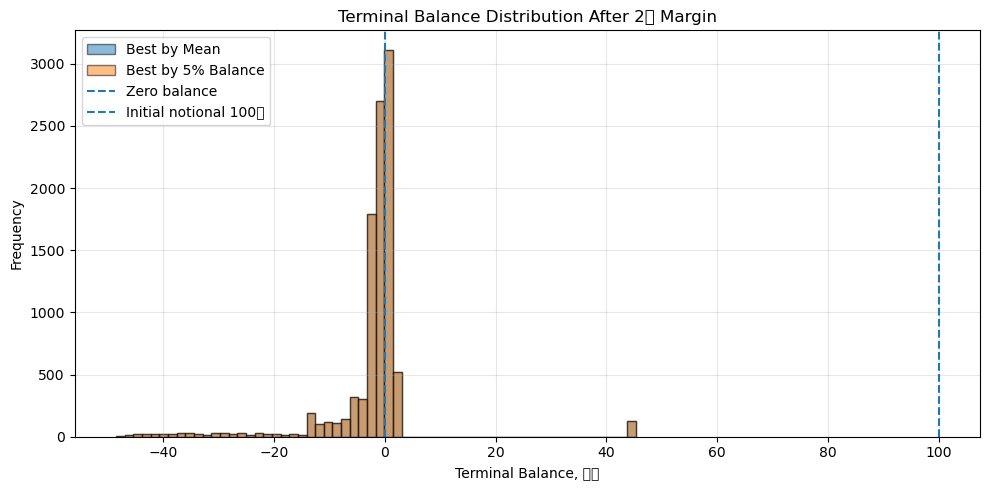

Saved figure to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\figures\section9_mean_vs_p05_distribution_after_margin.png


In [12]:
# ============================================================
# 9-10. Distribution Comparison: Mean vs 5% Strategy
# ============================================================

mean_tb = terminal_balance_with_margin_matrix[recommended_by_mean_id, :]
p05_tb = terminal_balance_with_margin_matrix[recommended_by_p05_id, :]

plt.figure(figsize=(10, 5))

plt.hist(
    mean_tb / 1e8,
    bins=60,
    alpha=0.5,
    edgecolor="black",
    label="Best by Mean"
)

plt.hist(
    p05_tb / 1e8,
    bins=60,
    alpha=0.5,
    edgecolor="black",
    label="Best by 5% Balance"
)

plt.axvline(0, linestyle="--", label="Zero balance")
plt.axvline(NOTIONAL / 1e8, linestyle="--", label="Initial notional 100억")

plt.title("Terminal Balance Distribution After 2억 Margin")
plt.xlabel("Terminal Balance, 억원")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

fig_path = FIGURE_DIR / "section9_mean_vs_p05_distribution_after_margin.png"
plt.savefig(fig_path, dpi=300)
plt.show()

print("Saved figure to:", fig_path)

# 9-11 component boxplot for mean strategy

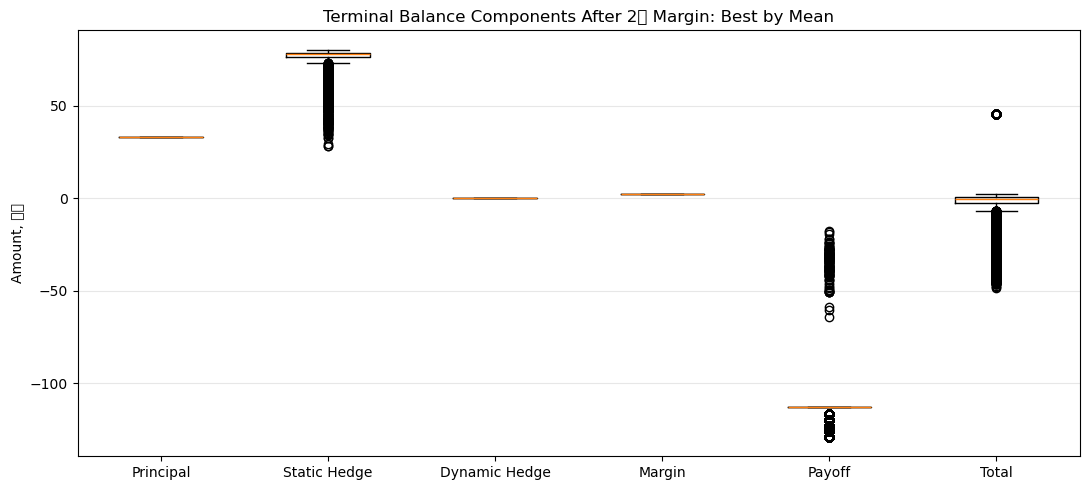

Saved figure to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\figures\section9_component_boxplot_best_by_mean.png


,count,mean,std,min,25%,50%,75%,max,mean_100m,p05_100m,p50_100m
Principal,"10,000.000000","3,281,431,751.075334",0.000317,"3,281,431,751.075334","3,281,431,751.075334","3,281,431,751.075334","3,281,431,751.075334","3,281,431,751.075334",32.814318,32.814318,32.814318
Static Hedge,"10,000.000000","7,662,708,213.730681","528,221,269.251686","2,811,188,032.629032","7,645,367,039.062248","7,770,135,522.572949","7,869,717,968.869704","8,029,159,320.461513",76.627082,72.325151,77.701355
Dynamic Hedge,"10,000.000000",0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Margin,"10,000.000000","218,762,116.738356",0.000027,"218,762,116.738356","218,762,116.738356","218,762,116.738356","218,762,116.738356","218,762,116.738356",2.187621,2.187621,2.187621
Payoff,"10,000.000000","-11,374,861,919.987413","1,006,270,138.966215","-12,910,000,000.000000","-11,300,187,287.841211","-11,300,187,287.841211","-11,300,187,287.841211","-1,782,028,712.167520",-113.748619,-129.100000,-113.001873
Total,"10,000.000000","-211,959,838.443041","891,498,892.568359","-4,850,147,385.841803","-246,208,668.934510","-68,769,734.494440","54,832,586.187668","4,529,353,188.275204",-2.119598,-13.806468,-0.687697


In [13]:
# ============================================================
# 9-11. Component Boxplot: Best by Mean
# ============================================================

component_mean_df = pd.DataFrame({
    "Principal": principal_account_terminal_matrix[recommended_by_mean_id, :],
    "Static Hedge": static_hedge_account_terminal_matrix[recommended_by_mean_id, :],
    "Dynamic Hedge": dynamic_terminal_account_matrix[recommended_by_mean_id, :],
    "Margin": margin_terminal_matrix[recommended_by_mean_id, :],
    "Payoff": -payoff_terminal_equivalent_matrix[recommended_by_mean_id, :],
    "Total": terminal_balance_with_margin_matrix[recommended_by_mean_id, :],
})

plt.figure(figsize=(11, 5))
plt.boxplot(
    [component_mean_df[col] / 1e8 for col in component_mean_df.columns],
    labels=component_mean_df.columns
)

plt.title("Terminal Balance Components After 2억 Margin: Best by Mean")
plt.ylabel("Amount, 억원")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()

fig_path = FIGURE_DIR / "section9_component_boxplot_best_by_mean.png"
plt.savefig(fig_path, dpi=300)
plt.show()

print("Saved figure to:", fig_path)

component_mean_summary = component_mean_df.describe().T
component_mean_summary["mean_100m"] = component_mean_summary["mean"] / 1e8
component_mean_summary["p05_100m"] = component_mean_df.quantile(0.05) / 1e8
component_mean_summary["p50_100m"] = component_mean_df.quantile(0.50) / 1e8
component_mean_summary

# 9-12 component boxplot for 5% strategy

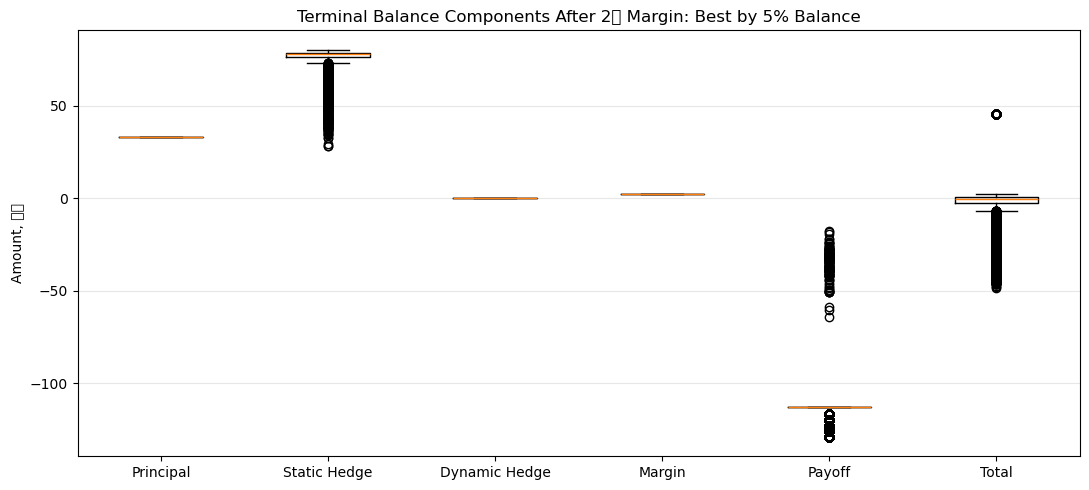

Saved figure to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\figures\section9_component_boxplot_best_by_p05.png


,count,mean,std,min,25%,50%,75%,max,mean_100m,p05_100m,p50_100m
Principal,"10,000.000000","3,281,431,751.075334",0.000317,"3,281,431,751.075334","3,281,431,751.075334","3,281,431,751.075334","3,281,431,751.075334","3,281,431,751.075334",32.814318,32.814318,32.814318
Static Hedge,"10,000.000000","7,662,708,213.730681","528,221,269.251686","2,811,188,032.629032","7,645,367,039.062248","7,770,135,522.572949","7,869,717,968.869704","8,029,159,320.461513",76.627082,72.325151,77.701355
Dynamic Hedge,"10,000.000000",0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Margin,"10,000.000000","218,762,116.738356",0.000027,"218,762,116.738356","218,762,116.738356","218,762,116.738356","218,762,116.738356","218,762,116.738356",2.187621,2.187621,2.187621
Payoff,"10,000.000000","-11,374,861,919.987413","1,006,270,138.966215","-12,910,000,000.000000","-11,300,187,287.841211","-11,300,187,287.841211","-11,300,187,287.841211","-1,782,028,712.167520",-113.748619,-129.100000,-113.001873
Total,"10,000.000000","-211,959,838.443041","891,498,892.568359","-4,850,147,385.841803","-246,208,668.934510","-68,769,734.494440","54,832,586.187668","4,529,353,188.275204",-2.119598,-13.806468,-0.687697


In [14]:
# ============================================================
# 9-12. Component Boxplot: Best by 5% Terminal Balance
# ============================================================

component_p05_df = pd.DataFrame({
    "Principal": principal_account_terminal_matrix[recommended_by_p05_id, :],
    "Static Hedge": static_hedge_account_terminal_matrix[recommended_by_p05_id, :],
    "Dynamic Hedge": dynamic_terminal_account_matrix[recommended_by_p05_id, :],
    "Margin": margin_terminal_matrix[recommended_by_p05_id, :],
    "Payoff": -payoff_terminal_equivalent_matrix[recommended_by_p05_id, :],
    "Total": terminal_balance_with_margin_matrix[recommended_by_p05_id, :],
})

plt.figure(figsize=(11, 5))
plt.boxplot(
    [component_p05_df[col] / 1e8 for col in component_p05_df.columns],
    labels=component_p05_df.columns
)

plt.title("Terminal Balance Components After 2억 Margin: Best by 5% Balance")
plt.ylabel("Amount, 억원")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()

fig_path = FIGURE_DIR / "section9_component_boxplot_best_by_p05.png"
plt.savefig(fig_path, dpi=300)
plt.show()

print("Saved figure to:", fig_path)

component_p05_summary = component_p05_df.describe().T
component_p05_summary["mean_100m"] = component_p05_summary["mean"] / 1e8
component_p05_summary["p05_100m"] = component_p05_df.quantile(0.05) / 1e8
component_p05_summary["p50_100m"] = component_p05_df.quantile(0.50) / 1e8
component_p05_summary

# 9-13 mean strategy vs 5% strategy comparison

In [15]:
# ============================================================
# 9-13. Mean Strategy vs 5% Strategy Comparison
# ============================================================

comparison_table = pd.DataFrame([
    {
        "criterion": "Best by Mean",
        "experiment_id": recommended_by_mean_id,
        "principal_book_ratio": recommended_by_mean["principal_book_ratio"],
        "hedge_book_ratio": recommended_by_mean["hedge_book_ratio"],
        "static_ratio": recommended_by_mean["static_ratio"],
        "dynamic_ratio": recommended_by_mean["dynamic_ratio"],
        "mean_balance_100m": recommended_by_mean["mean_terminal_balance_after_margin"] / 1e8,
        "std_balance_100m": recommended_by_mean["std_terminal_balance_after_margin"] / 1e8,
        "p05_balance_100m": recommended_by_mean["p05_terminal_balance_after_margin"] / 1e8,
        "p50_balance_100m": recommended_by_mean["p50_terminal_balance_after_margin"] / 1e8,
        "prob_negative": recommended_by_mean["prob_negative_after_margin"],
        "prob_below_notional": recommended_by_mean["prob_below_notional_after_margin"],
        "risk_adjusted_score_100m": recommended_by_mean["risk_adjusted_score_after_margin"] / 1e8,
    },
    {
        "criterion": "Best by 5% Balance",
        "experiment_id": recommended_by_p05_id,
        "principal_book_ratio": recommended_by_p05["principal_book_ratio"],
        "hedge_book_ratio": recommended_by_p05["hedge_book_ratio"],
        "static_ratio": recommended_by_p05["static_ratio"],
        "dynamic_ratio": recommended_by_p05["dynamic_ratio"],
        "mean_balance_100m": recommended_by_p05["mean_terminal_balance_after_margin"] / 1e8,
        "std_balance_100m": recommended_by_p05["std_terminal_balance_after_margin"] / 1e8,
        "p05_balance_100m": recommended_by_p05["p05_terminal_balance_after_margin"] / 1e8,
        "p50_balance_100m": recommended_by_p05["p50_terminal_balance_after_margin"] / 1e8,
        "prob_negative": recommended_by_p05["prob_negative_after_margin"],
        "prob_below_notional": recommended_by_p05["prob_below_notional_after_margin"],
        "risk_adjusted_score_100m": recommended_by_p05["risk_adjusted_score_after_margin"] / 1e8,
    },
    {
        "criterion": "Best by Risk-adjusted Score",
        "experiment_id": recommended_by_score_id,
        "principal_book_ratio": recommended_by_score["principal_book_ratio"],
        "hedge_book_ratio": recommended_by_score["hedge_book_ratio"],
        "static_ratio": recommended_by_score["static_ratio"],
        "dynamic_ratio": recommended_by_score["dynamic_ratio"],
        "mean_balance_100m": recommended_by_score["mean_terminal_balance_after_margin"] / 1e8,
        "std_balance_100m": recommended_by_score["std_terminal_balance_after_margin"] / 1e8,
        "p05_balance_100m": recommended_by_score["p05_terminal_balance_after_margin"] / 1e8,
        "p50_balance_100m": recommended_by_score["p50_terminal_balance_after_margin"] / 1e8,
        "prob_negative": recommended_by_score["prob_negative_after_margin"],
        "prob_below_notional": recommended_by_score["prob_below_notional_after_margin"],
        "risk_adjusted_score_100m": recommended_by_score["risk_adjusted_score_after_margin"] / 1e8,
    },
])

comparison_table

,criterion,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,mean_balance_100m,std_balance_100m,p05_balance_100m,p50_balance_100m,prob_negative,prob_below_notional,risk_adjusted_score_100m
0,Best by Mean,10,0.300000,0.700000,1.000000,0.000000,-2.119598,8.914989,-13.806468,-0.687697,0.632800,1.000000,-6.577093
1,Best by 5% Balance,10,0.300000,0.700000,1.000000,0.000000,-2.119598,8.914989,-13.806468,-0.687697,0.632800,1.000000,-6.577093
2,Best by Risk-adjusted Score,10,0.300000,0.700000,1.000000,0.000000,-2.119598,8.914989,-13.806468,-0.687697,0.632800,1.000000,-6.577093


## 수정: Section 9 마진/수수료 및 거래비용 민감도 재분석

아래 코드는 기존 section 3~7 산출물을 재사용하되, 동적헤지 계좌는 거래비용을 반영해 다시 계산한다. 거래비용은 점수에서 임의 차감하지 않고 실제 리밸런싱 시점의 현금 차감으로 처리한다. 정적헤지는 short put open premium과 close value에 option 거래비용 bps를 적용해 만기시점 가치로 환산한 뒤 terminal balance에서 차감한다.


In [16]:
# ============================================================
# 9-14. Margin/Fee and Transaction Cost Sensitivity Reanalysis
# 수정: 2% 마진/수수료 성격과 동적/정적 거래비용을 분리해 재분석
# ============================================================

# --- Load additional hedge inputs ---
paths = np.load(OUTPUT_DIR / "mc_paths.npy")
S_GRID = np.load(OUTPUT_DIR / "fdm_S_GRID.npy")
delta_ki_grid = np.load(OUTPUT_DIR / "fdm_delta_ki_grid.npy")
delta_noki_grid = np.load(OUTPUT_DIR / "fdm_delta_noki_grid.npy")
static_metadata_df = pd.read_csv(OUTPUT_DIR / "static_hedge_metadata.csv")
static_close_df = pd.read_csv(OUTPUT_DIR / "static_put_close_by_path.csv")

KNOCK_IN_BARRIER = 0.35
S0 = 100.0
ki_level = KNOCK_IN_BARRIER * S0
ki_state_matrix = np.minimum.accumulate(paths, axis=1) <= ki_level

N_PATHS, N_TIME = paths.shape
N_STEPS = N_TIME - 1
REBALANCE_FREQ = 5
weekly_rebal_indices = np.arange(0, N_STEPS + 1, REBALANCE_FREQ)
settlement_indices = payoff_df["settlement_index"].astype(int).unique()
trading_indices = np.unique(
    np.concatenate([
        weekly_rebal_indices,
        settlement_indices,
        np.array([N_STEPS])
    ])
)
trading_indices = np.sort(trading_indices)


def lookup_delta_vectorized_for_section9(
    S_values,
    time_index,
    ki_states,
    S_GRID,
    delta_ki_grid,
    delta_noki_grid
):
    time_index = int(np.clip(time_index, 0, delta_ki_grid.shape[0] - 1))
    S_clipped = np.clip(S_values, S_GRID[0], S_GRID[-1])
    delta_noki = np.interp(S_clipped, S_GRID, delta_noki_grid[time_index, :])
    delta_ki = np.interp(S_clipped, S_GRID, delta_ki_grid[time_index, :])
    return np.where(ki_states, delta_ki, delta_noki)


def cash_growth_factor_by_days(n_days, daily_rate=PRINCIPAL_DAILY_RATE):
    return (1 + daily_rate) ** n_days


def run_dynamic_hedge_with_transaction_cost(
    row,
    paths,
    payoff_df,
    trading_indices,
    ki_state_matrix,
    S_GRID,
    delta_ki_grid,
    delta_noki_grid,
    transaction_cost_bps=0.0,
    principal_daily_rate=PRINCIPAL_DAILY_RATE
):
    n_paths, n_time = paths.shape
    n_steps = n_time - 1
    dynamic_ratio = float(row["dynamic_ratio"])
    dynamic_budget = float(row["dynamic_budget"])
    tc_rate = transaction_cost_bps * 1e-4
    settlement_index = payoff_df["settlement_index"].astype(int).values

    cash = np.full(n_paths, dynamic_budget, dtype=float)
    units = np.zeros(n_paths, dtype=float)
    active = np.ones(n_paths, dtype=bool)

    turnover = np.zeros(n_paths)
    transaction_cost_paid = np.zeros(n_paths)
    num_rebalances = np.zeros(n_paths, dtype=int)
    max_abs_position_value = np.zeros(n_paths)

    last_idx = 0

    for idx in trading_indices:
        idx = int(idx)
        n_days = idx - last_idx
        if n_days > 0:
            cash *= cash_growth_factor_by_days(
                n_days=n_days,
                daily_rate=principal_daily_rate
            )

        S_t = paths[:, idx]

        settle_now = active & (settlement_index == idx)
        if np.any(settle_now):
            close_notional = np.abs(units[settle_now] * S_t[settle_now])
            close_cost = tc_rate * close_notional
            cash[settle_now] += units[settle_now] * S_t[settle_now]
            cash[settle_now] -= close_cost
            turnover[settle_now] += close_notional
            transaction_cost_paid[settle_now] += close_cost
            units[settle_now] = 0.0
            active[settle_now] = False

        rebalance_now = active
        if np.any(rebalance_now):
            S_active = S_t[rebalance_now]
            ki_active = ki_state_matrix[rebalance_now, idx]

            liability_delta = lookup_delta_vectorized_for_section9(
                S_values=S_active,
                time_index=idx,
                ki_states=ki_active,
                S_GRID=S_GRID,
                delta_ki_grid=delta_ki_grid,
                delta_noki_grid=delta_noki_grid
            )

            target_units_uncapped = liability_delta * dynamic_ratio
            position_value_uncapped = target_units_uncapped * S_active
            abs_position_value = np.abs(position_value_uncapped)

            cap_factor = np.ones_like(target_units_uncapped)
            binding = abs_position_value > dynamic_budget
            cap_factor[binding] = dynamic_budget / (abs_position_value[binding] + 1e-12)
            target_units = target_units_uncapped * cap_factor

            old_units = units[rebalance_now]
            trade_units = target_units - old_units
            trade_notional = np.abs(trade_units * S_active)
            transaction_cost = tc_rate * trade_notional

            cash[rebalance_now] -= trade_units * S_active
            cash[rebalance_now] -= transaction_cost
            units[rebalance_now] = target_units

            turnover[rebalance_now] += trade_notional
            transaction_cost_paid[rebalance_now] += transaction_cost
            num_rebalances[rebalance_now] += 1
            max_abs_position_value[rebalance_now] = np.maximum(
                max_abs_position_value[rebalance_now],
                np.abs(target_units * S_active)
            )

        last_idx = idx

    final_S = paths[:, -1]
    still_active = active
    if np.any(still_active):
        close_notional = np.abs(units[still_active] * final_S[still_active])
        close_cost = tc_rate * close_notional
        cash[still_active] += units[still_active] * final_S[still_active]
        cash[still_active] -= close_cost
        turnover[still_active] += close_notional
        transaction_cost_paid[still_active] += close_cost
        units[still_active] = 0.0
        active[still_active] = False

    idle_terminal_account = dynamic_budget * cash_growth_factor_by_days(
        n_days=n_steps,
        daily_rate=principal_daily_rate
    )

    metadata = {
        "transaction_cost_bps": transaction_cost_bps,
        "dynamic_ratio": dynamic_ratio,
        "dynamic_budget": dynamic_budget,
        "mean_turnover": np.mean(turnover),
        "p95_turnover": np.percentile(turnover, 95),
        "mean_transaction_cost_paid": np.mean(transaction_cost_paid),
        "p95_transaction_cost_paid": np.percentile(transaction_cost_paid, 95),
        "mean_num_rebalances": np.mean(num_rebalances),
        "mean_max_abs_position_value": np.mean(max_abs_position_value),
        "idle_terminal_account": idle_terminal_account,
    }

    return cash, metadata


def static_option_transaction_cost_terminal_matrix(option_tc_bps):
    tc_rate = option_tc_bps * 1e-4
    matrix = np.zeros((n_experiments, n_paths))
    put_close_price = static_close_df["put_close_price"].astype(float).values

    for i, row in static_metadata_df.iterrows():
        actual_units = float(row["actual_units"])
        initial_put_price = float(row["initial_put_price"])
        open_cost = tc_rate * actual_units * initial_put_price
        close_cost_by_path = tc_rate * actual_units * put_close_price
        matrix[i, :] = (
            open_cost * growth_full_maturity
            + close_cost_by_path * growth_settlement_to_maturity
        )

    return matrix


margin_fee_scenarios = [
    {
        "margin_fee_scenario": "no_margin_or_fee",
        "initial_cash_adjustment": 0.0,
        "interpretation": "No additional 2% cashflow is retained or paid.",
    },
    {
        "margin_fee_scenario": "issuer_margin_retained_2pct",
        "initial_cash_adjustment": 0.02 * NOTIONAL,
        "interpretation": "2% is retained by issuer and invested to maturity.",
    },
    {
        "margin_fee_scenario": "sales_fee_paid_2pct",
        "initial_cash_adjustment": -0.02 * NOTIONAL,
        "interpretation": "2% is paid out as sales fee at issuance.",
    },
]

dynamic_tc_bps_grid = [0, 1, 5, 10, 20, 50]
static_option_tc_bps_grid = [0, 5]

# Dynamic hedge accounts by transaction cost scenario.
dynamic_account_by_tc = {}
dynamic_tc_metadata_rows = []

for tc_bps in dynamic_tc_bps_grid:
    dynamic_account_matrix_tc = np.zeros_like(dynamic_terminal_account_matrix)

    for i, row in experiment_grid.iterrows():
        terminal_account_tc, metadata_tc = run_dynamic_hedge_with_transaction_cost(
            row=row,
            paths=paths,
            payoff_df=payoff_df,
            trading_indices=trading_indices,
            ki_state_matrix=ki_state_matrix,
            S_GRID=S_GRID,
            delta_ki_grid=delta_ki_grid,
            delta_noki_grid=delta_noki_grid,
            transaction_cost_bps=tc_bps,
            principal_daily_rate=PRINCIPAL_DAILY_RATE
        )
        dynamic_account_matrix_tc[i, :] = terminal_account_tc
        dynamic_tc_metadata_rows.append({
            "experiment_id": int(row["experiment_id"]),
            "principal_book_ratio": row["principal_book_ratio"],
            "hedge_book_ratio": row["hedge_book_ratio"],
            "static_ratio": row["static_ratio"],
            "dynamic_ratio": row["dynamic_ratio"],
            **metadata_tc,
        })

    dynamic_account_by_tc[tc_bps] = dynamic_account_matrix_tc
    print(f"Finished dynamic transaction cost scenario: {tc_bps} bps")

dynamic_tc_metadata = pd.DataFrame(dynamic_tc_metadata_rows)

# Reanalysis summary.
reanalysis_rows = []
static_cost_cache = {
    option_tc_bps: static_option_transaction_cost_terminal_matrix(option_tc_bps)
    for option_tc_bps in static_option_tc_bps_grid
}

for margin_case in margin_fee_scenarios:
    margin_fee_terminal_value = margin_case["initial_cash_adjustment"] * growth_full_maturity

    for dynamic_tc_bps in dynamic_tc_bps_grid:
        dynamic_account_tc = dynamic_account_by_tc[dynamic_tc_bps]

        for static_option_tc_bps in static_option_tc_bps_grid:
            static_cost_terminal = static_cost_cache[static_option_tc_bps]

            scenario_terminal_balance_matrix = (
                principal_account_terminal_matrix
                + static_hedge_account_terminal_matrix
                - static_cost_terminal
                + dynamic_account_tc
                - payoff_terminal_equivalent_matrix
                + margin_fee_terminal_value
            )

            for i, row in experiment_grid.iterrows():
                tb = scenario_terminal_balance_matrix[i, :]
                p05 = np.percentile(tb, 5)
                cvar05 = tb[tb <= p05].mean()

                reanalysis_rows.append({
                    "margin_fee_scenario": margin_case["margin_fee_scenario"],
                    "initial_cash_adjustment": margin_case["initial_cash_adjustment"],
                    "margin_fee_terminal_value": margin_fee_terminal_value,
                    "dynamic_tc_bps": dynamic_tc_bps,
                    "static_option_tc_bps": static_option_tc_bps,
                    "experiment_id": int(row["experiment_id"]),
                    "principal_book_ratio": row["principal_book_ratio"],
                    "hedge_book_ratio": row["hedge_book_ratio"],
                    "static_ratio": row["static_ratio"],
                    "dynamic_ratio": row["dynamic_ratio"],
                    "mean_terminal_balance": np.mean(tb),
                    "std_terminal_balance": np.std(tb, ddof=1),
                    "p01_terminal_balance": np.percentile(tb, 1),
                    "p05_terminal_balance": p05,
                    "cvar05_terminal_balance": cvar05,
                    "p50_terminal_balance": np.percentile(tb, 50),
                    "prob_negative_balance": np.mean(tb < 0),
                    "capital_required_95": max(-p05, 0),
                })

section9_reanalysis_summary = pd.DataFrame(reanalysis_rows)
section9_reanalysis_summary["risk_adjusted_score"] = (
    section9_reanalysis_summary["mean_terminal_balance"]
    - 0.5 * section9_reanalysis_summary["std_terminal_balance"]
)

scenario_keys = [
    "margin_fee_scenario",
    "dynamic_tc_bps",
    "static_option_tc_bps",
]

best_by_scenario_p05 = (
    section9_reanalysis_summary
    .sort_values("p05_terminal_balance", ascending=False)
    .groupby(scenario_keys, as_index=False)
    .head(1)
    .reset_index(drop=True)
)

best_by_scenario_mean = (
    section9_reanalysis_summary
    .sort_values("mean_terminal_balance", ascending=False)
    .groupby(scenario_keys, as_index=False)
    .head(1)
    .reset_index(drop=True)
)

best_by_scenario_score = (
    section9_reanalysis_summary
    .sort_values("risk_adjusted_score", ascending=False)
    .groupby(scenario_keys, as_index=False)
    .head(1)
    .reset_index(drop=True)
)

best_by_scenario = pd.concat([
    best_by_scenario_mean.assign(selection_criterion="max_mean"),
    best_by_scenario_p05.assign(selection_criterion="max_p05"),
    best_by_scenario_score.assign(selection_criterion="max_risk_adjusted_score"),
], ignore_index=True)

money_cols = [
    "initial_cash_adjustment",
    "margin_fee_terminal_value",
    "mean_terminal_balance",
    "std_terminal_balance",
    "p01_terminal_balance",
    "p05_terminal_balance",
    "cvar05_terminal_balance",
    "p50_terminal_balance",
    "capital_required_95",
    "risk_adjusted_score",
]

for df in [section9_reanalysis_summary, best_by_scenario, dynamic_tc_metadata]:
    for col in money_cols:
        if col in df.columns:
            df[col + "_100m"] = df[col] / 1e8

print("Reanalysis summary rows:", len(section9_reanalysis_summary))
print("Best-by-scenario rows:", len(best_by_scenario))
display(best_by_scenario.head(20))


Finished dynamic transaction cost scenario: 0 bps
Finished dynamic transaction cost scenario: 1 bps
Finished dynamic transaction cost scenario: 5 bps
Finished dynamic transaction cost scenario: 10 bps
Finished dynamic transaction cost scenario: 20 bps
Finished dynamic transaction cost scenario: 50 bps
Reanalysis summary rows: 1188
Best-by-scenario rows: 108


,margin_fee_scenario,initial_cash_adjustment,margin_fee_terminal_value,dynamic_tc_bps,static_option_tc_bps,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,mean_terminal_balance,std_terminal_balance,p01_terminal_balance,p05_terminal_balance,cvar05_terminal_balance,p50_terminal_balance,prob_negative_balance,capital_required_95,risk_adjusted_score,selection_criterion,initial_cash_adjustment_100m,margin_fee_terminal_value_100m,mean_terminal_balance_100m,std_terminal_balance_100m,p01_terminal_balance_100m,p05_terminal_balance_100m,cvar05_terminal_balance_100m,p50_terminal_balance_100m,capital_required_95_100m,risk_adjusted_score_100m
0,issuer_margin_retained_2pct,"200,000,000.000000","218,762,116.738356",5,0,10,0.300000,0.700000,1.000000,0.000000,"-211,959,838.443041","891,498,892.568358","-3,888,185,997.152192","-1,380,646,811.724798","-2,698,081,611.155080","-68,769,734.494440",0.632800,"1,380,646,811.724798","-657,709,284.727220",max_mean,2.000000,2.187621,-2.119598,8.914989,-38.881860,-13.806468,-26.980816,-0.687697,13.806468,-6.577093
1,issuer_margin_retained_2pct,"200,000,000.000000","218,762,116.738356",20,0,10,0.300000,0.700000,1.000000,0.000000,"-211,959,838.443041","891,498,892.568358","-3,888,185,997.152192","-1,380,646,811.724798","-2,698,081,611.155080","-68,769,734.494440",0.632800,"1,380,646,811.724798","-657,709,284.727220",max_mean,2.000000,2.187621,-2.119598,8.914989,-38.881860,-13.806468,-26.980816,-0.687697,13.806468,-6.577093
2,issuer_margin_retained_2pct,"200,000,000.000000","218,762,116.738356",50,0,10,0.300000,0.700000,1.000000,0.000000,"-211,959,838.443041","891,498,892.568358","-3,888,185,997.152192","-1,380,646,811.724798","-2,698,081,611.155080","-68,769,734.494440",0.632800,"1,380,646,811.724798","-657,709,284.727220",max_mean,2.000000,2.187621,-2.119598,8.914989,-38.881860,-13.806468,-26.980816,-0.687697,13.806468,-6.577093
3,issuer_margin_retained_2pct,"200,000,000.000000","218,762,116.738356",10,0,10,0.300000,0.700000,1.000000,0.000000,"-211,959,838.443041","891,498,892.568358","-3,888,185,997.152192","-1,380,646,811.724798","-2,698,081,611.155080","-68,769,734.494440",0.632800,"1,380,646,811.724798","-657,709,284.727220",max_mean,2.000000,2.187621,-2.119598,8.914989,-38.881860,-13.806468,-26.980816,-0.687697,13.806468,-6.577093
4,issuer_margin_retained_2pct,"200,000,000.000000","218,762,116.738356",1,0,10,0.300000,0.700000,1.000000,0.000000,"-211,959,838.443041","891,498,892.568358","-3,888,185,997.152192","-1,380,646,811.724798","-2,698,081,611.155080","-68,769,734.494440",0.632800,"1,380,646,811.724798","-657,709,284.727220",max_mean,2.000000,2.187621,-2.119598,8.914989,-38.881860,-13.806468,-26.980816,-0.687697,13.806468,-6.577093
5,issuer_margin_retained_2pct,"200,000,000.000000","218,762,116.738356",0,0,10,0.300000,0.700000,1.000000,0.000000,"-211,959,838.443041","891,498,892.568358","-3,888,185,997.152192","-1,380,646,811.724798","-2,698,081,611.155080","-68,769,734.494440",0.632800,"1,380,646,811.724798","-657,709,284.727220",max_mean,2.000000,2.187621,-2.119598,8.914989,-38.881860,-13.806468,-26.980816,-0.687697,13.806468,-6.577093
6,issuer_margin_retained_2pct,"200,000,000.000000","218,762,116.738356",1,5,10,0.300000,0.700000,1.000000,0.000000,"-212,329,224.129266","891,516,099.148031","-3,889,625,948.144345","-1,380,832,993.124237","-2,698,926,509.954234","-69,104,856.163323",0.633500,"1,380,832,993.124237","-658,087,273.703281",max_mean,2.000000,2.187621,-2.123292,8.915161,-38.896259,-13.808330,-26.989265,-0.691049,13.808330,-6.580873
7,issuer_margin_retained_2pct,"200,000,000.000000","218,762,116.738356",10,5,10,0.300000,0.700000,1.000000,0.000000,"-212,329,224.129266","891,516,099.148031","-3,889,625,948.144345","-1,380,832,993.124237","-2,698,926,509.954234","-69,104,856.163323",0.633500,"1,380,832,993.124237","-658,087,273.703281",max_mean,2.000000,2.187621,-2.123292,8.915161,-38.896259,-13.808330,-26.989265,-0.691049,13.808330,-6.580873
8,issuer_margin_

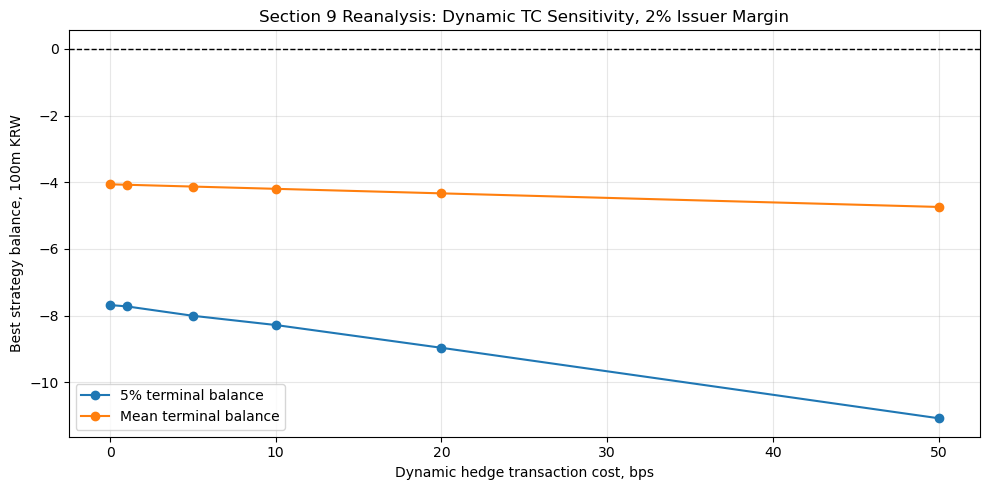

Saved section 9 reanalysis summary to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\section9_reanalysis_scenario_summary.csv
Saved section 9 best-by-scenario to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\section9_reanalysis_best_by_scenario.csv
Saved dynamic transaction cost metadata to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\section9_dynamic_transaction_cost_metadata.csv
Saved interpretation text to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\section9_reanalysis_interpretation.txt
Saved figure to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\figures\section9_reanalysis_dynamic_tc_sensitivity.png
Section 9 수정 재분석 요약

1. 2%를 발행자가 보유하는 마진으로 보면 terminal balance는 2억원의 만기시점 가치만큼 개선된다.
2. 2%를 외부 판매수수료로 지급한다고 보면 같은 금액만큼 terminal balance가 악화된다.
3. 거래비용은 objective score에서 임의 차감하지 않고 리밸런싱 cash account와 static short put open/close 비용에서 직접 차감했다.
4. 예시 기준(issuer_margin_retained_2pct, dynamic_tc=10bp, static_option_tc=5bp, max_p05)의 최적 조합은 experiment 

In [17]:
# ============================================================
# 9-15. Save Reanalysis Outputs
# 수정: section 9 재분석 산출물 저장
# ============================================================

section9_reanalysis_summary_path = OUTPUT_DIR / "section9_reanalysis_scenario_summary.csv"
section9_best_by_scenario_path = OUTPUT_DIR / "section9_reanalysis_best_by_scenario.csv"
section9_dynamic_tc_metadata_path = OUTPUT_DIR / "section9_dynamic_transaction_cost_metadata.csv"
section9_interpretation_path = OUTPUT_DIR / "section9_reanalysis_interpretation.txt"

section9_reanalysis_summary.to_csv(
    section9_reanalysis_summary_path,
    index=False,
    encoding="utf-8-sig"
)

best_by_scenario.to_csv(
    section9_best_by_scenario_path,
    index=False,
    encoding="utf-8-sig"
)

dynamic_tc_metadata.to_csv(
    section9_dynamic_tc_metadata_path,
    index=False,
    encoding="utf-8-sig"
)

plot_df = best_by_scenario[
    (best_by_scenario["selection_criterion"] == "max_p05")
    & (best_by_scenario["margin_fee_scenario"] == "issuer_margin_retained_2pct")
    & (best_by_scenario["static_option_tc_bps"] == 5)
].copy()
plot_df = plot_df.sort_values("dynamic_tc_bps")

plt.figure(figsize=(10, 5))
plt.plot(
    plot_df["dynamic_tc_bps"],
    plot_df["p05_terminal_balance_100m"],
    marker="o",
    label="5% terminal balance"
)
plt.plot(
    plot_df["dynamic_tc_bps"],
    plot_df["mean_terminal_balance_100m"],
    marker="o",
    label="Mean terminal balance"
)
plt.axhline(0, linestyle="--", color="black", linewidth=1)
plt.title("Section 9 Reanalysis: Dynamic TC Sensitivity, 2% Issuer Margin")
plt.xlabel("Dynamic hedge transaction cost, bps")
plt.ylabel("Best strategy balance, 100m KRW")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

fig_path = FIGURE_DIR / "section9_reanalysis_dynamic_tc_sensitivity.png"
plt.savefig(fig_path, dpi=300)
plt.show()

base_case = best_by_scenario[
    (best_by_scenario["selection_criterion"] == "max_p05")
    & (best_by_scenario["margin_fee_scenario"] == "issuer_margin_retained_2pct")
    & (best_by_scenario["dynamic_tc_bps"] == 10)
    & (best_by_scenario["static_option_tc_bps"] == 5)
].iloc[0]

fee_case = best_by_scenario[
    (best_by_scenario["selection_criterion"] == "max_p05")
    & (best_by_scenario["margin_fee_scenario"] == "sales_fee_paid_2pct")
    & (best_by_scenario["dynamic_tc_bps"] == 10)
    & (best_by_scenario["static_option_tc_bps"] == 5)
].iloc[0]

interpretation_lines = [
    "Section 9 수정 재분석 요약",
    "",
    "1. 2%를 발행자가 보유하는 마진으로 보면 terminal balance는 2억원의 만기시점 가치만큼 개선된다.",
    "2. 2%를 외부 판매수수료로 지급한다고 보면 같은 금액만큼 terminal balance가 악화된다.",
    "3. 거래비용은 objective score에서 임의 차감하지 않고 리밸런싱 cash account와 static short put open/close 비용에서 직접 차감했다.",
    f"4. 예시 기준(issuer_margin_retained_2pct, dynamic_tc=10bp, static_option_tc=5bp, max_p05)의 최적 조합은 experiment {int(base_case['experiment_id'])}, 원금북 {base_case['principal_book_ratio']:.0%}, 헤지북 {base_case['hedge_book_ratio']:.0%}, 정적 {base_case['static_ratio']:.0%}, 동적 {base_case['dynamic_ratio']:.0%}이다. 이때 평균 잔고는 {base_case['mean_terminal_balance_100m']:.2f}억원, 5% 잔고는 {base_case['p05_terminal_balance_100m']:.2f}억원이다.",
    f"5. 같은 비용 조건에서 2%가 판매수수료로 지급되면 max_p05 최적 조합의 평균 잔고는 {fee_case['mean_terminal_balance_100m']:.2f}억원, 5% 잔고는 {fee_case['p05_terminal_balance_100m']:.2f}억원이다.",
]
interpretation_text = "\n".join(interpretation_lines)

with open(section9_interpretation_path, "w", encoding="utf-8") as f:
    f.write(interpretation_text)

print("Saved section 9 reanalysis summary to:", section9_reanalysis_summary_path)
print("Saved section 9 best-by-scenario to:", section9_best_by_scenario_path)
print("Saved dynamic transaction cost metadata to:", section9_dynamic_tc_metadata_path)
print("Saved interpretation text to:", section9_interpretation_path)
print("Saved figure to:", fig_path)
print(interpretation_text)
